# Experimento 5 — Boosting melhora a previsão?

**Hipótese:** árvores com boosting reduzem o erro ao representar curvaturas e interações. Comparamos a regressão do notebook 06 com `HistGradientBoostingRegressor`, usando os mesmos seis atributos: duas médias, afinidade, afinidade² e dois indicadores de gênero.

### Configuração proposta

| Parâmetro | Valores | Finalidade |
|---|---|---|
| `max_leaf_nodes` | 7, 15 | Limitar complexidade |
| `min_samples_leaf` | 20, 60 | Controlar tamanho das folhas |
| `l2_regularization` | 0, 10 | Penalizar valores das folhas |
| `learning_rate` | 0,05 | Tamanho fixo dos passos |
| `max_iter` | 200 | Número fixo de etapas |
| `early_stopping` | False | Manter esse orçamento |

São oito configurações, escolhidas por RMSE em 3 dobras internas de cada treino externo: 600 ajustes internos, 25 reajustes de boosting e 25 regressões. A busca pode demorar. Alterar a grade após ver a validação externa constitui nova exploração.

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
N_BINS = 8  # Somente visualização; não modifica os modelos.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
genres = ['action', 'comedy', 'drama']
assert set(df['genre'].unique()).issubset(genres)
required = ['user_avg_stars', 'movie_avg_stars', 'stars'] + ['share_' + g for g in genres]
assert not df[required].isna().any().any()
df['affinity'] = [row['share_' + row['genre']] for _, row in df.iterrows()]
assert df['affinity'].between(0, 1).all()
y = df['stars'].to_numpy(dtype=float)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
display(df[['genre', 'share_action', 'share_comedy', 'share_drama', 'affinity']].head())
print(f'{len(df)} linhas; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')
df['affinity2'] = df['affinity'] ** 2

# Ação é a referência; categorias conhecidas não são aprendidas no conjunto.
df['genre_comedy'] = df['genre'].eq('comedy').astype(float)
df['genre_drama'] = df['genre'].eq('drama').astype(float)
BASE_FEATURES = ['user_avg_stars', 'movie_avg_stars', 'affinity', 'affinity2']
GENRE_FEATURES = BASE_FEATURES + ['genre_comedy', 'genre_drama']


,genre,share_action,share_comedy,share_drama,affinity
0,drama,0.315,0.501,0.184,0.184
1,action,0.180,0.151,0.669,0.180
2,action,0.701,0.258,0.041,0.701
3,action,0.700,0.204,0.096,0.700
4,action,0.621,0.257,0.122,0.621


4000 linhas; 5 folds × 5 repetições; semente 2026; corte: True


In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid
from sklearn.metrics import make_scorer

INNER_SPLITS = 3
PARAM_GRID = {
    'max_leaf_nodes': [7, 15],
    'min_samples_leaf': [20, 60],
    'l2_regularization': [0.0, 10.0],
}
BOOSTING_FIXED = dict(learning_rate=0.05, max_iter=200, early_stopping=False, random_state=SEED)
display(pd.DataFrame(list(ParameterGrid(PARAM_GRID))))
print('Configuração fixa:', BOOSTING_FIXED)


,l2_regularization,max_leaf_nodes,min_samples_leaf
0,0.0,7,20
1,0.0,7,60
2,0.0,15,20
3,0.0,15,60
4,10.0,7,20
5,10.0,7,60
6,10.0,15,20
7,10.0,15,60


Configuração fixa: {'learning_rate': 0.05, 'max_iter': 200, 'early_stopping': False, 'random_state': 2026}


In [3]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

def predict_checked(model, X):
    # Equação explícita evita os avisos locais de matmul na regressão.
    prediction = (np.sum(X * model.coef_, axis=1) + model.intercept_
                  if isinstance(model, LinearRegression) else model.predict(X))
    assert np.isfinite(prediction).all()
    return np.clip(prediction, 0, 5) if CLIP else prediction


In [4]:
def selection_rmse(actual, predicted):
    predicted = np.clip(predicted, 0, 5) if CLIP else predicted
    return rmse(actual, predicted)

scorer = make_scorer(selection_rmse, greater_is_better=False)
candidates = {'Regressão com gênero': GENRE_FEATURES, 'Boosting': GENRE_FEATURES}
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
predictions_by_repeat = {name: np.full((N_REPEATS, len(df)), np.nan) for name in candidates}
rows, selections = [], []
X = df[GENRE_FEATURES].to_numpy(dtype=float)
for partition, (train, valid) in enumerate(folds):
    for name in candidates:
        if name == 'Boosting':
            search = GridSearchCV(
                HistGradientBoostingRegressor(**BOOSTING_FIXED), PARAM_GRID,
                scoring=scorer, cv=KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED),
                n_jobs=1, error_score='raise', refit=True)
            search.fit(X[train], y[train])
            model = search.best_estimator_
            selections.append({'particao': partition + 1, **search.best_params_,
                               'RMSE interno selecionado': -search.best_score_})
        else:
            model = LinearRegression().fit(X[train], y[train])
        pred = predict_checked(model, X[valid])
        predictions_by_repeat[name][partition // N_SPLITS, valid] = pred
        rows.append({'modelo': name, 'particao': partition + 1,
                     'E_CV': rmse(y[valid], pred),
                     'E_in': rmse(y[train], predict_checked(model, X[train]))})
assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
by_fold = pd.DataFrame(rows)
summary = by_fold.groupby('modelo', sort=False).agg(
    E_CV=('E_CV', 'mean'),
    desvio_E_CV=('E_CV', 'std'),
    E_in=('E_in', 'mean'))
summary.insert(0, 'RMSE OOF repetido', [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(4))
paired = by_fold.pivot(index='particao', columns='modelo', values='E_CV')
reference, candidate = list(candidates)
paired['Candidato − referência'] = paired[candidate] - paired[reference]
display(paired.round(4))
print(f"Candidato melhora em {int((paired['Candidato − referência'] < 0).sum())}/{len(folds)} partições.")
per_repeat = pd.DataFrame({name: [rmse(y, pred) for pred in values]
                           for name, values in predictions_by_repeat.items()},
                          index=pd.Index(range(1, N_REPEATS + 1), name='repetição'))
per_repeat['Candidato − referência'] = per_repeat[candidate] - per_repeat[reference]
display(per_repeat.round(4))


,RMSE OOF repetido,E_CV,desvio_E_CV,E_in
modelo,,,,
Regressão com gênero,0.6250,0.6249,0.0148,0.6234
Boosting,0.6192,0.6191,0.0132,0.5655


modelo,Boosting,Regressão com gênero,Candidato − referência
particao,,,
1,0.6268,0.6256,0.0012
2,0.6081,0.6216,-0.0135
3,0.6115,0.6146,-0.0031
4,0.6234,0.6397,-0.0163
5,0.6190,0.6215,-0.0025
6,0.6333,0.6424,-0.0091
7,0.6307,0.6267,0.0040
8,0.6047,0.6135,-0.0088
9,0.6202,0.6204,-0.0003


Candidato melhora em 20/25 partições.


,Regressão com gênero,Boosting,Candidato − referência
repetição,,,
1,0.6247,0.6178,-0.0069
2,0.6249,0.6206,-0.0043
3,0.6251,0.6198,-0.0053
4,0.6250,0.6176,-0.0074
5,0.6255,0.6204,-0.0051


## 1. Configurações e diagnóstico

Observe a estabilidade dos hiperparâmetros e o erro externo. O RMSE interno seleciona a configuração; não substitui a avaliação externa. A escolha entre famílias continua exploratória.

,particao,l2_regularization,max_leaf_nodes,min_samples_leaf,RMSE interno selecionado
0,1,10.0,7,20,0.624561
1,2,0.0,7,20,0.626665
2,3,0.0,7,20,0.627915
3,4,0.0,7,20,0.623715
4,5,0.0,7,20,0.625932
5,6,0.0,7,20,0.626950
6,7,10.0,7,20,0.618224
7,8,0.0,7,20,0.626251
8,9,0.0,7,20,0.620838
9,10,0.0,7,20,0.627145


,modelo,gênero,n,resíduo médio,RMSE OOF repetido
0,Regressão com gênero,action,1462,0.0319,0.6212
1,Regressão com gênero,comedy,1254,0.0086,0.6382
2,Regressão com gênero,drama,1284,0.0241,0.6163
3,Boosting,action,1462,-0.0008,0.6188
4,Boosting,comedy,1254,-0.0145,0.6303
5,Boosting,drama,1284,0.0132,0.6088


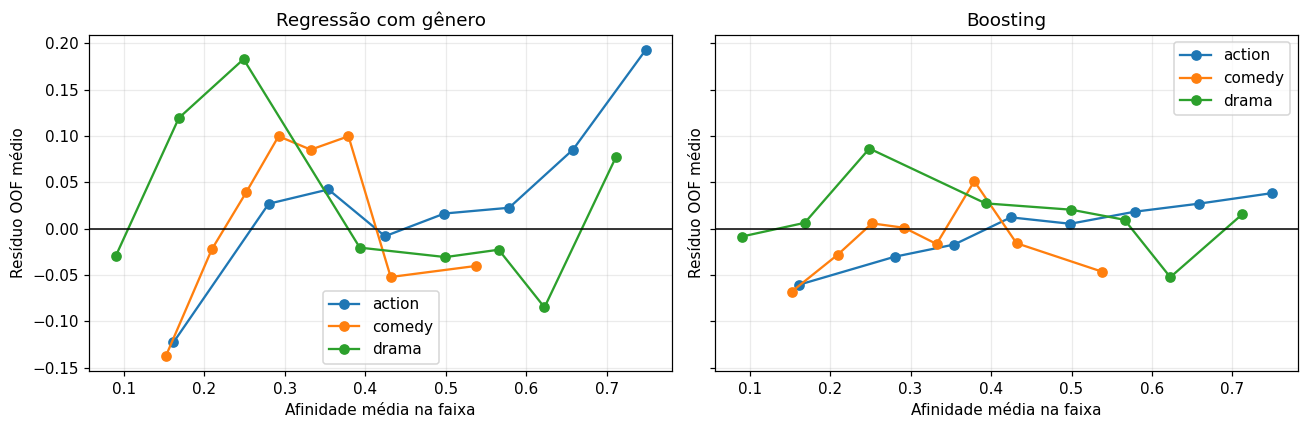

In [5]:
display(pd.DataFrame(selections))
residuals = oof.apply(lambda prediction: y - prediction)
rows_genre = []
for name in candidates:
    for genre in genres:
        mask = df['genre'].eq(genre).to_numpy()
        rows_genre.append({'modelo': name, 'gênero': genre, 'n': int(mask.sum()),
                          'resíduo médio': residuals.loc[mask, name].mean(),
                          'RMSE OOF repetido': rmse(y[mask], predictions_by_repeat[name][:, mask])})
display(pd.DataFrame(rows_genre).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, candidates):
    for genre in genres:
        sub = df.loc[df['genre'].eq(genre), ['affinity']].copy()
        sub['residuo'] = residuals.loc[sub.index, name]
        table = sub.groupby(pd.qcut(sub['affinity'], N_BINS, duplicates='drop'), observed=True).agg(
            x=('affinity', 'mean'), residuo=('residuo', 'mean'))
        ax.plot(table['x'], table['residuo'], 'o-', label=genre)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title=name, xlabel='Afinidade média na faixa', ylabel='Resíduo OOF médio')
    ax.legend()
plt.tight_layout()
plt.show()


## 2. Conclusão do grupo

- O ganho é relevante e consistente, com menos padrões nos resíduos?
- A distância entre $E_{in}$ e $E_{CV}$ sugere sobreajuste?
- O ganho compensa o custo e a menor facilidade de interpretação?

**Questões para discussão após a execução registrada abaixo.** O resultado vale para a grade testada; não selecionamos o modelo final aqui.

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '07_comparacao_boosting', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/mrm/Documents/Disciplinas/Apredizagem Estatística/movie-rating-prediction/results/rodada_atual/07_comparacao_boosting.json


## Leitura da execução de 15 de novembro de 2026

Boosting obteve RMSE OOF repetido **0,619248**, contra **0,625036** da regressão com gênero: redução de **0,005788**, cerca de **0,93%**, com melhora em **20/25 partições** e nas cinco repetições. A flexibilidade trouxe ganho modesto nesta grade.

O $E_{in}$ médio foi **0,565527** no boosting e **0,623377** na regressão. A diferença média por partição entre $E_{CV}$ e $E_{in}$ foi **0,053584** no boosting, contra **0,001491** na regressão. Há maior adaptação ao treino; a melhora externa existe, mas não permite declarar ausência de sobreajuste.

As 25 buscas escolheram **7 folhas**, o menor limite da grade. A folha mínima foi 20 em 24 partições e 60 em uma. A penalização foi 0 em 18 partições e 10 em sete. Não ampliamos a grade após ver esses resultados. O notebook 09 reúne as comparações e procura padrões restantes antes de decidir outro experimento.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.